In [140]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import kagglehub
import seaborn as sns
import os

# **Define reusable functions**

In [141]:
def print_line(num):
    print('=' * num)
    
def print_txt(text, num=50):
    print_line(num)
    print(text)
    print_line(num)

In [142]:
def show_plot(column, title, x_label, y_label, x_ticks, figsize=(12, 5), marker='o'):
    
    plt.figure(figsize=figsize)

    plt.plot(column.index, column.values, marker=marker)

    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)

    plt.xticks( *x_ticks)

    plt.grid()
    plt.show()

In [143]:
# uncomment to import from kaggle 

raw_data_path = kagglehub.dataset_download("karapy/azure-1")

print("Path to dataset files:", raw_data_path)

Path to dataset files: /kaggle/input/datasets/karapy/azure-1


In [144]:
clean_data_path = kagglehub.dataset_download("karapy/azure-1-processed")

print("Path to dataset files:", clean_data_path)

Path to dataset files: /kaggle/input/datasets/karapy/azure-1-processed


In [145]:
# for i in os.walk('../input'):
#     print(i)

In [146]:
RAW_DATA_DIR = Path.joinpath(Path(raw_data_path), 'dataset-electric.csv')
CLEAN_DATA = Path.joinpath(Path(clean_data_path), 'cleaned_dataset-electric.csv')

# RAW_DATA_DIR = '../data/raw/dataset-electric.csv'
# SAVE_DATA_DIR = Path('../data/processed/')
# CLEAN_DATA = 'cleaned_dataset-electric.csv'

In [147]:
# for i in os.walk('..'):
#     print(i)

In [148]:
print_txt('import the raw dataset & display first and last 5 rows')
df = pd.read_csv(RAW_DATA_DIR)
display(df.head())
print_line(50)
display(df.tail())


import the raw dataset & display first and last 5 rows


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


,Datetime,PJME_MW
145361,2018-01-01 20:00:00,44284.0
145362,2018-01-01 21:00:00,43751.0
145363,2018-01-01 22:00:00,42402.0
145364,2018-01-01 23:00:00,40164.0
145365,2018-01-02 00:00:00,38608.0


In [149]:
print_txt('avaible columns')

print(f'Columns : {df.columns.to_list()}')

avaible columns
Columns : ['Datetime', 'PJME_MW']


In [150]:
print_txt('display a discriptive data about datafram€')
display(df.describe())

display a discriptive data about datafram€


,PJME_MW
count,145366.000000
mean,32080.222831
std,6464.012166
min,14544.000000
25%,27573.000000
50%,31421.000000
75%,35650.000000
max,62009.000000


In [151]:
print_txt('Get the shape of the dataframe')

print(f'shape   : {df.shape}')
print(f'rows    : {df.shape[0]}')
print(f'columns : {df.shape[1]}')

Get the shape of the dataframe
shape   : (145366, 2)
rows    : 145366
columns : 2


In [152]:
print_txt('check for missing values ')
display(df.isna().sum())

check for missing values 


Datetime    0
PJME_MW     0
dtype: int64

In [153]:
print_txt('check for duplicates ')
display(df.duplicated().sum())

check for duplicates 


np.int64(0)

In [154]:
print_txt('show columns data types')
df.info()

show columns data types
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  object 
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.2+ MB


In [155]:
clean_df = pd.read_csv(CLEAN_DATA)

# clean_df = pd.read_csv(Path.joinpath(SAVE_DATA_DIR, CLEAN_DATA))

In [156]:
print_txt('check if there is a duplicated datetime')

# include the first appearence keep=false
d_mask = clean_df['Datetime'].duplicated(keep=False)

clean_df.loc[d_mask]


check if there is a duplicated datetime


,Datetime,PJME_MW


In [157]:
# reconvert to datetime
clean_df['Datetime'] = pd.to_datetime(clean_df['Datetime'])

In [158]:
print_txt('Investigate consumption anomalies')
print('first 10 rows after sorting')
# print_line(20)
display(clean_df['PJME_MW'].sort_values(ascending=True).head(10))
print_line(20)
print('last 10 rows after sorting')
display(clean_df['PJME_MW'].sort_values(ascending=True).tail(10))

Investigate consumption anomalies
first 10 rows after sorting


94923    14544.0
94922    14586.0
94924    14821.0
94921    14955.0
94920    15390.0
94925    15526.0
94919    15919.0
94926    16688.0
94918    17422.0
94927    17734.0
Name: PJME_MW, dtype: float64

last 10 rows after sorting


83749    61532.0
83751    61608.0
40193    61610.0
40190    61641.0
40168    61643.0
83750    61646.0
40215    61770.0
40216    61796.0
40191    61909.0
40192    62009.0
Name: PJME_MW, dtype: float64

## **Daily Average Electricity Consumption Over Time**

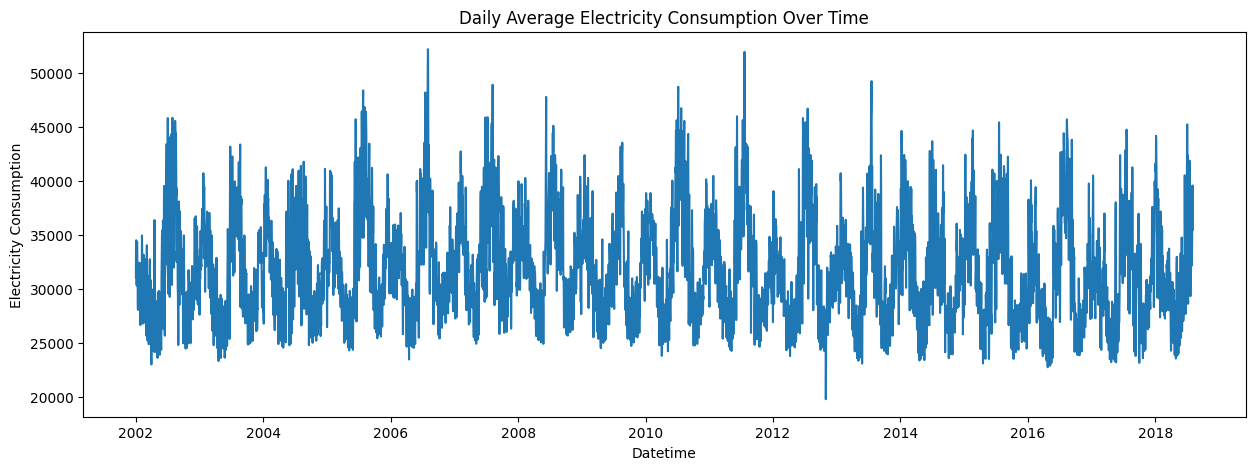

In [159]:
daily_df = clean_df.set_index('Datetime')['PJME_MW'].resample('d').mean()

plt.figure(figsize=(15, 5))
plt.plot(daily_df)

plt.title('Daily Average Electricity Consumption Over Time')
plt.xlabel('Datetime')
plt.ylabel('Electricity Consumption')

plt.show()

## **Average Electricity Consumption by Hour**

In [160]:
print_txt('calculate the average consuption per hour')

hourly_consumption = clean_df.groupby(clean_df['Datetime'].dt.hour)['PJME_MW'].mean()

display(hourly_consumption)

calculate the average consuption per hour


Datetime
0     29524.588808
1     27535.589964
2     26340.725322
3     25676.398977
4     25414.924728
5     25749.431000
6     27162.853912
7     29611.046880
8     31490.827831
9     32628.888247
10    33497.403433
11    34197.643117
12    34588.618356
13    34759.571146
14    34916.601684
15    34940.669693
16    35065.392209
17    35596.051502
18    36421.931496
19    36426.629911
20    36106.840211
21    35741.057280
22    34453.149884
23    32047.501486
Name: PJME_MW, dtype: float64

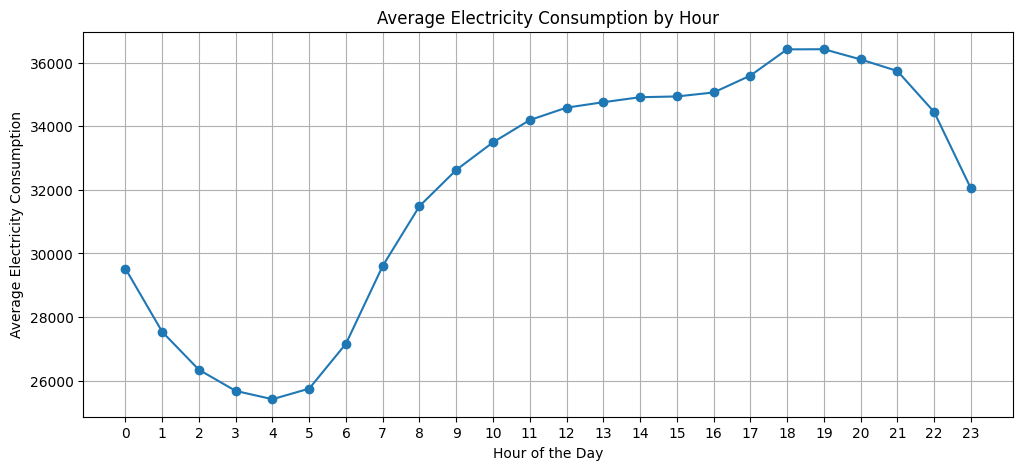

In [161]:
show_plot(hourly_consumption, 'Average Electricity Consumption by Hour', 'Hour of the Day', 'Average Electricity Consumption', [range(24), range(24)])

## **Average Electricity Consumption by Day of Week**

In [162]:
daily_consumption = clean_df.groupby(clean_df['Datetime'].dt.dayofweek )['PJME_MW'].mean()

print_txt('calculate the average consuption per day')

display(daily_consumption)

calculate the average consuption per day


Datetime
0    32672.028420
1    33272.265746
2    33261.497498
3    33085.857727
4    32688.230528
5    30162.880588
6    29405.871821
Name: PJME_MW, dtype: float64

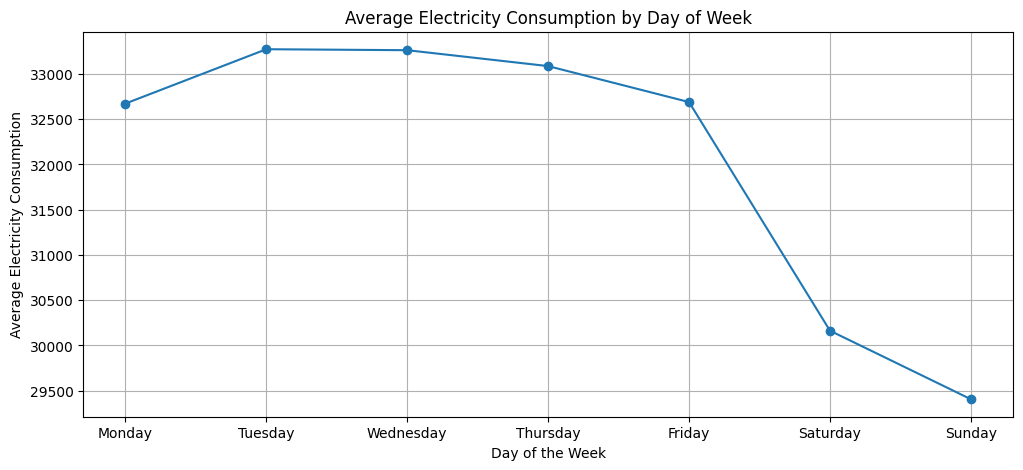

In [163]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',  'Friday', 'Saturday', 'Sunday']

show_plot(daily_consumption, 'Average Electricity Consumption by Day of Week', 'Day of the Week', 'Average Electricity Consumption', [range(7), days])


## **Average Electricity Consumption by Month**

In [164]:
monthly_consumption = clean_df.groupby(clean_df['Datetime'].dt.month )['PJME_MW'].mean()


print_txt('calculate the average consuption per month')

display(monthly_consumption)

calculate the average consuption per month


Datetime
1     34343.246462
2     33434.972049
3     30510.017868
4     27861.419036
5     28695.362113
6     33811.799183
7     37881.972881
8     36595.959675
9     31484.054688
10    28117.006762
11    29327.731033
12    32676.480343
Name: PJME_MW, dtype: float64

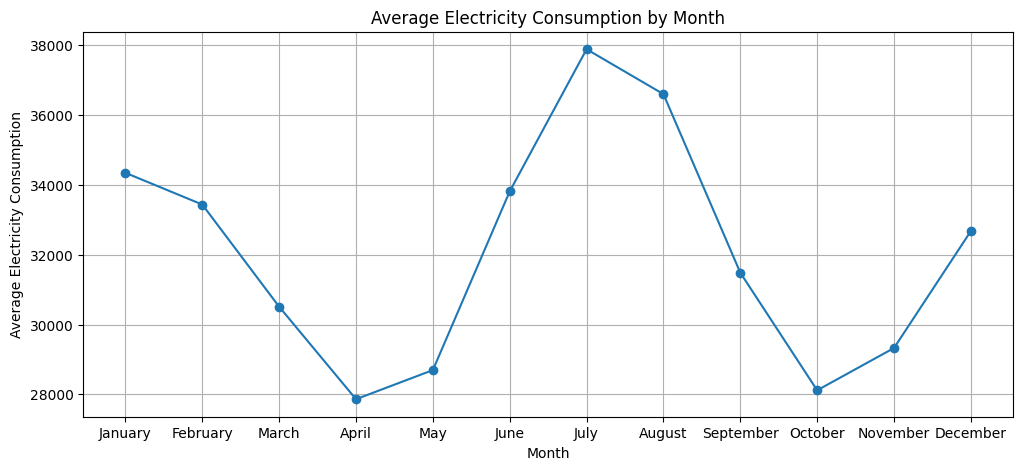

In [165]:
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
show_plot(monthly_consumption, 'Average Electricity Consumption by Month', 'Month', 'Average Electricity Consumption', [range(1, 13), months])

In [166]:
print_txt('Monthly electricity consumption over the years')

monthly_trend = clean_df.set_index('Datetime')['PJME_MW'].resample('MS').mean()

display(monthly_trend.head())

Monthly electricity consumption over the years


Datetime
2002-01-01    31075.399731
2002-02-01    30239.166667
2002-03-01    28875.256720
2002-04-01    28529.284028
2002-05-01    28073.653226
Freq: MS, Name: PJME_MW, dtype: float64

## **Monthly consumption over the years**

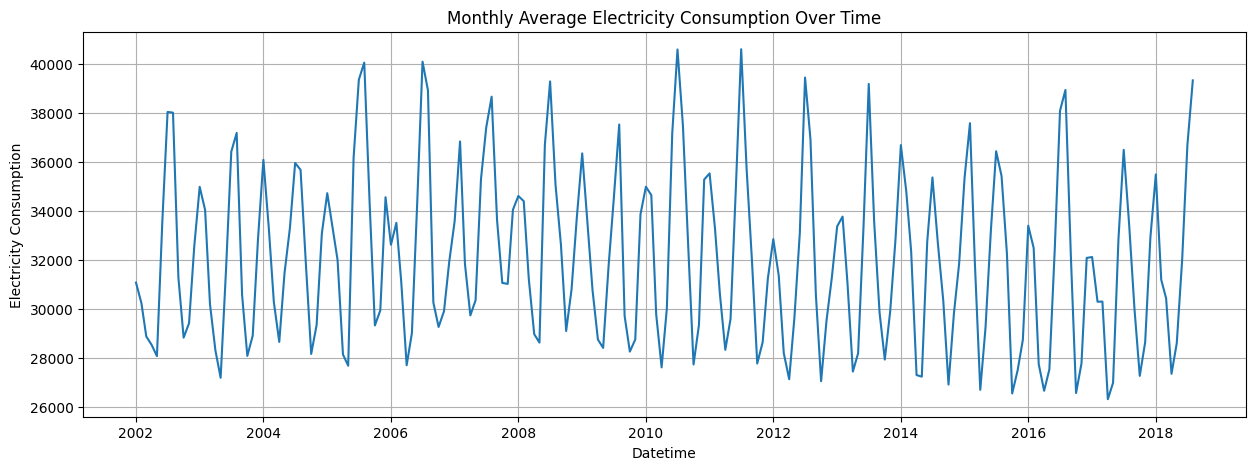

In [167]:
plt.figure(figsize=(15, 5))
plt.plot(monthly_trend)

plt.title('Monthly Average Electricity Consumption Over Time')
plt.xlabel('Datetime')
plt.ylabel('Electricity Consumption')

plt.grid()
plt.show()

# Inspict datetime

In [168]:
mask = clean_df['Datetime'].diff() > pd.Timedelta(hours=1)


# make a copy of the Datetime

gap_info = clean_df.loc[mask, ['Datetime']].copy()
gap_info['gap'] = clean_df['Datetime'].diff().loc[mask]
gap_info['previous_datetime'] = clean_df['Datetime'].shift(1).loc[mask]
gap_info['missing_hours'] = (gap_info['gap'] / pd.Timedelta(hours=1) - 1)

print('Number of gaps      :', len(gap_info))
print('Total missing hours :', gap_info['missing_hours'].sum())
display(gap_info)

Number of gaps      : 0
Total missing hours : 0.0


,Datetime,gap,previous_datetime,missing_hours


In [169]:
clean_df.loc[clean_df['Datetime'].diff() > pd.Timedelta(hours=1)]

,Datetime,PJME_MW


In [170]:
print_txt('Missing hours distribution')

display(gap_info['missing_hours'].value_counts().sort_index())

Missing hours distribution


Series([], Name: count, dtype: int64)

In [171]:
display(gap_info)

,Datetime,gap,previous_datetime,missing_hours
